In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from lime.lime_text import LimeTextExplainer

In [2]:
data = pd.read_excel("sample data.xlsx")

In [3]:
text_cols = [f"Q{i}_CH" for i in range(1, 34) if i != 22]
data["combined_text"] = (
    data[text_cols]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)

# use gender as target for logistic regression
targetvariable = "gender"
data_1 = data.loc[
    data[targetvariable].isin(["Man", "Woman"])
    & data["combined_text"].ne("")
].copy()

In [4]:
# Split participants: 80% training / 20% testing
train, test = train_test_split(
    data_1,
    test_size=0.20,
    random_state=806,
    stratify=data_1[targetvariable])

In [5]:
# TF-IDF and logistic regression
model = make_pipeline(
    TfidfVectorizer(
        min_df=5,
        max_features=2000,
        stop_words="english"
    ),
    LogisticRegression(
        max_iter=1000,
        random_state=806
    )
)

model.fit(train["combined_text"], train[targetvariable])

Pipeline(steps=[('tfidfvectorizer',
                 TfidfVectorizer(max_features=2000, min_df=5,
                                 stop_words='english')),
                ('logisticregression',
                 LogisticRegression(max_iter=1000, random_state=806))])

In [6]:
predictions = model.predict(test["combined_text"])
majority_class = train[targetvariable].mode()[0]
print("Model accuracy:",round(accuracy_score(test[targetvariable], predictions), 3))

Model accuracy: 0.647


In [7]:
class_names = model.classes_.tolist()
explainer = LimeTextExplainer(class_names=class_names,random_state=806)


Participant ID: 57
Self-reported gender: Woman
Predicted category: Man
Probabilities: {'Man': 0.673, 'Woman': 0.327}


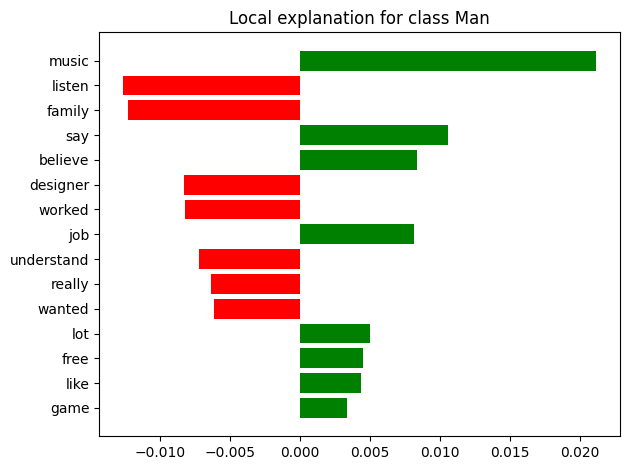


Local explanation weights:
music: +0.021
listen: -0.013
family: -0.012
say: +0.011
believe: +0.008
designer: -0.008
worked: -0.008
job: +0.008
understand: -0.007
really: -0.006
wanted: -0.006
lot: +0.005
free: +0.004
like: +0.004
game: +0.003


In [9]:
# select a participant and explain predicted category
person_index = 0
person = test.iloc[person_index]
person_text = person["combined_text"]

probabilities = model.predict_proba([person_text])[0]
predicted_class_index = int(np.argmax(probabilities))

print("\nParticipant ID:", person["ID"])
print("Self-reported gender:", person[targetvariable])
print("Predicted category:", class_names[predicted_class_index])
print("Probabilities:", dict(zip(class_names, probabilities.round(3))))

explanation = explainer.explain_instance(
    person_text,
    model.predict_proba,
    labels=[predicted_class_index],
    num_features=15,
    num_samples=5000
)

explanation.as_pyplot_figure(label=predicted_class_index)
plt.tight_layout()
plt.show()

print("\nLocal explanation weights:")
for word, weight in explanation.as_list(label=predicted_class_index):
    print(f"{word}: {weight:+.3f}")